# Datenexploration

## Init

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path)

# Explorative Datenanalyse (EDA)

In [3]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Dateninspektion
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1152 entries, 0 to 1151
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Unnamed: 0  1152 non-null   int64         
 1   date        1152 non-null   datetime64[ns]
 2   n_sick      1152 non-null   int64         
 3   calls       1152 non-null   float64       
 4   n_duty      1152 non-null   int64         
 5   n_sby       1152 non-null   int64         
 6   sby_need    1152 non-null   float64       
 7   dafted      1152 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(4)
memory usage: 72.1 KB
None
        Unnamed: 0                 date       n_sick         calls  \
count  1152.000000                 1152  1152.000000   1152.000000   
mean    575.500000  2017-10-28 12:00:00    68.808160   7919.531250   
min       0.000000  2016-04-01 00:00:00    36.000000   4074.000000   
25%     287.750000  2017-01-13 18:00:00    58.000000   6978

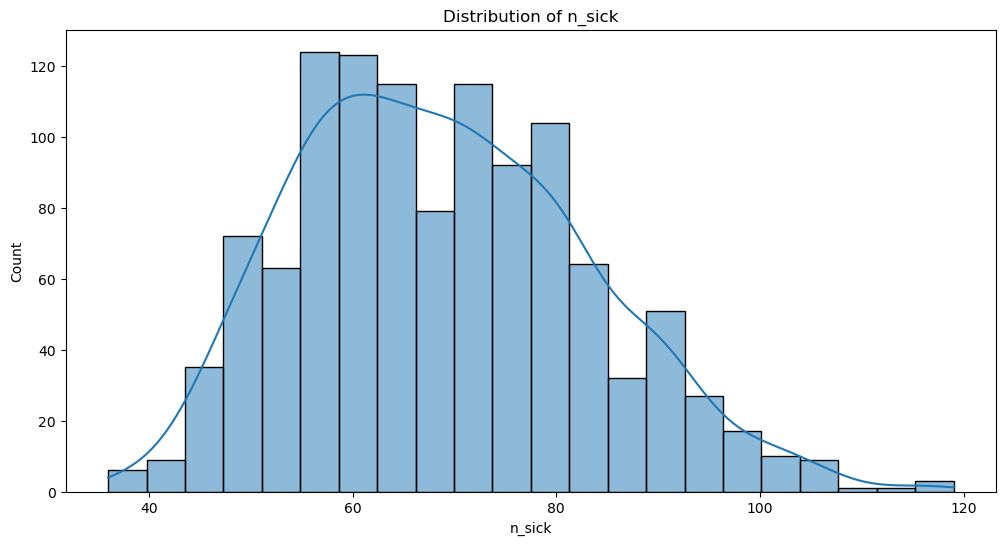

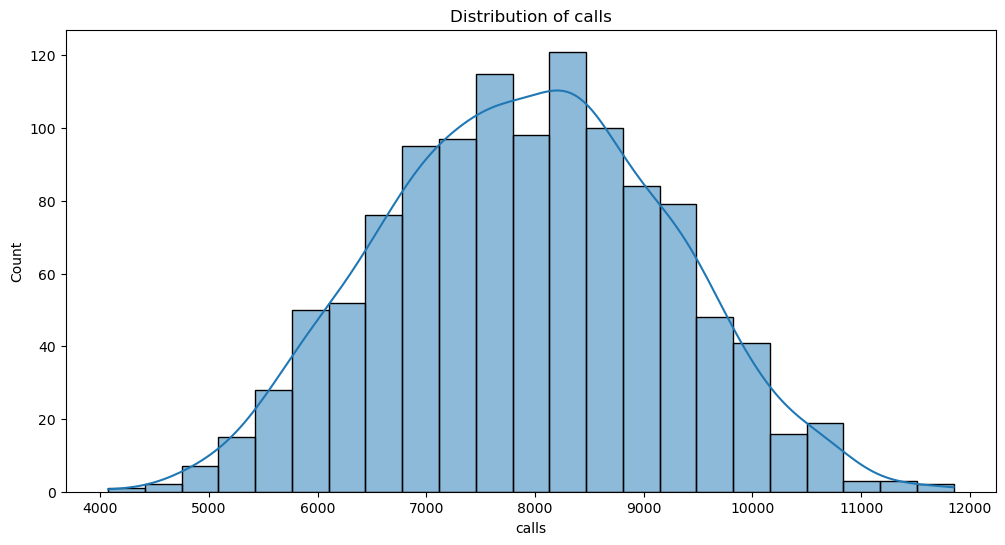

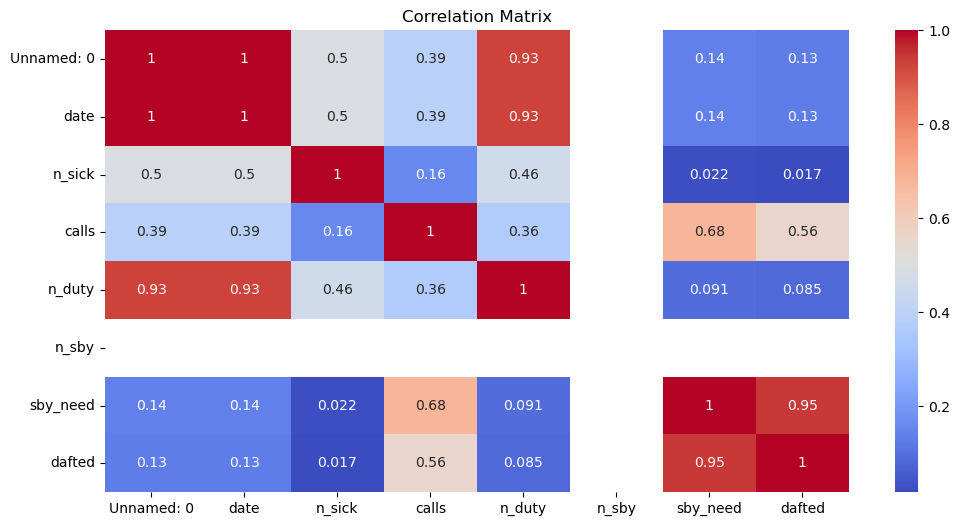

In [20]:
# Visualisierungen
plt.figure(figsize=(12, 6))
sns.histplot(df['n_sick'], kde=True)
plt.title('Distribution of n_sick')
plt.show()

plt.figure(figsize=(12, 6))
sns.histplot(df['calls'], kde=True)
plt.title('Distribution of calls')
plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#To-Do: Visualiserung auf X-Achse noch nicht aussagekräftig und Verteilung der Anrufe ist evtl. auch nicht ideal

# Datenvorbereitung

In [21]:
working_df = df.copy(deep=True)

print("Number NaN values:", working_df.isna().sum())

# Umgang mit fehlenden Werten
working_df = working_df.dropna()

# Feature Engineering
working_df['month'] = working_df['date'].dt.month
working_df['day_of_week'] = working_df['date'].dt.dayofweek

# Datenaufteilung
from sklearn.model_selection import train_test_split

X = working_df[['calls', 'n_duty', 'n_sby', 'sby_need', 'dafted', 'month', 'day_of_week']]
y = working_df['n_sick']  # Annahme: n_sick soll vorhergesagt werden

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Number NaN values: Unnamed: 0    0
date          0
n_sick        0
calls         0
n_duty        0
n_sby         0
sby_need      0
dafted        0
dtype: int64


## Baseline-Modell

Baseline MAE: 11.855563546117295


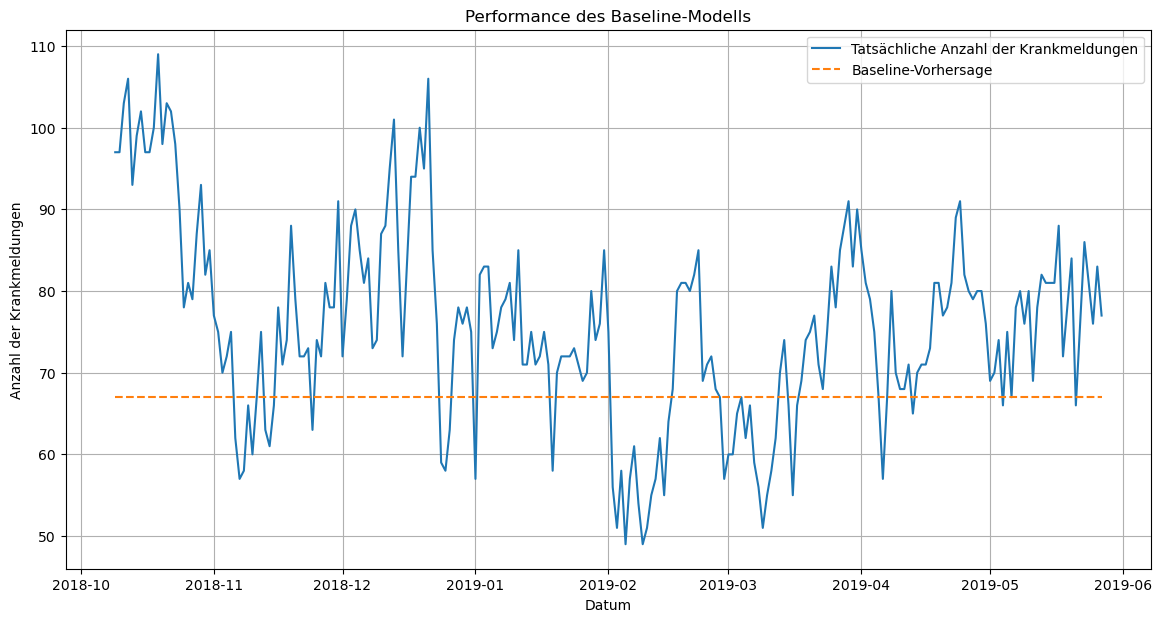

In [28]:
train_size = int(len(working_df) * 0.8)
train, test = working_df.iloc[:train_size], working_df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
mean_sick_train = train['n_sick'].mean()


test = test.copy() # Zum Verhindern der SettingWithCopyWarning
# Vorhersagen für das Testset mit dem Baseline-Modell
test['baseline_pred'] = mean_sick_train

# Berechnung des Mean Absolute Error (MAE) für das Baseline-Modell
mae_baseline = mean_absolute_error(test['n_sick'], test['baseline_pred'])
print(f'Baseline MAE: {mae_baseline}')

# Visualisierung der Performance des Baseline-Modells
plt.figure(figsize=(14, 7))
plt.plot(test['date'], test['n_sick'], label='Tatsächliche Anzahl der Krankmeldungen')
plt.plot(test['date'], test['baseline_pred'], label='Baseline-Vorhersage', linestyle='--')
plt.xlabel('Datum')
plt.ylabel('Anzahl der Krankmeldungen')
plt.title('Performance des Baseline-Modells')
plt.legend()
plt.grid(True)
plt.show()

## Erstellung und Evaluation des Vorhersagemodells

Model MAE: 7.693878169449599
Best Model MAE: 7.510964253818184

Feature importance:
n_sby: 0.0
dafted: 0.009627249342095823
sby_need: 0.020269338358201217
day_of_week: 0.0728957530585713
calls: 0.1828387038508894
n_duty: 0.2762772792958437
month: 0.43809167609439853



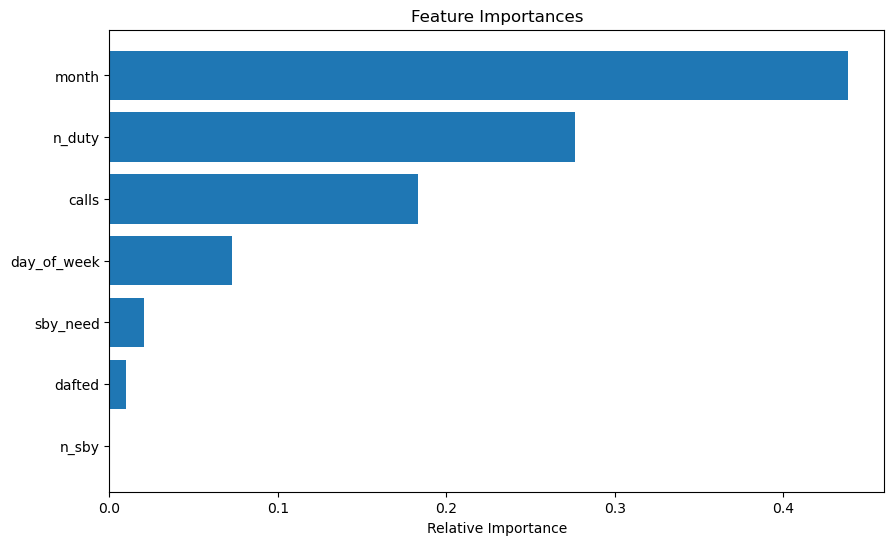

In [24]:
# Auswahl und Training eines Modells
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Model MAE: {mean_absolute_error(y_test, y_pred)}')

# Hyperparameter-Tuning (optional)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_absolute_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print(f'Best Model MAE: {mean_absolute_error(y_test, y_pred_best)}')

# Visualisierung und Kommunikation der Ergebnisse

# Feature Importance
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

print("\nFeature importance:")
[print(features[i] + ":", importances[i]) for i in indices]
print("")

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()